# Clustering

In [1]:
# Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.colors import LogNorm
from matplotlib.ticker import FixedLocator, FixedFormatter

from sklearn.cluster import KMeans, DBSCAN, SpectralClustering, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import silhouette_score, silhouette_samples

from sklearn.datasets import make_moons

Dataset yang akan digunakan dalam modul ini adalah data iris dan data moon. Keduanya adalah dataset bawaan dari scikit-learn.<br>
Catatan: dataset Iris sebetulnya memiliki nilai target (supervised), tetapi bisa kita gunakan untuk belajar teknik clustering (unsupervised).

### Helper Functions

In [2]:
def plot_data(X):
    plt.plot(X[:, 0], X[:, 1], 'k.', markersize=2)

def plot_centroids(centroids, weights=None, circle_color='w', cross_color='k'):
    if weights is not None:
        centroids = centroids[weights > weights.max() / 10]
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker='o', s=35, linewidths=8,
                color=circle_color, zorder=10, alpha=0.9)
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker='x', s=2, linewidths=12,
                color=cross_color, zorder=11, alpha=1)

def plot_decision_boundaries(clusterer, X, resolution=1000, show_centroids=True,
                             show_xlabels=True, show_ylabels=True):
    mins = X.min(axis=0) - 0.1
    maxs = X.max(axis=0) + 0.1
    xx, yy = np.meshgrid(np.linspace(mins[0], maxs[0], resolution),
                         np.linspace(mins[1], maxs[1], resolution))
    Z = clusterer.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.contourf(Z, extent=(mins[0], maxs[0], mins[1], maxs[1]),
                cmap="Pastel2")
    plt.contour(Z, extent=(mins[0], maxs[0], mins[1], maxs[1]),
                linewidths=1, colors='k')
    plot_data(X)
    if show_centroids:
        plot_centroids(clusterer.cluster_centers_)

    if show_xlabels:
        plt.xlabel("petal length")
    else:
        plt.tick_params(labelbottom=False)
    if show_ylabels:
        plt.ylabel("petal width ", rotation=1)
    else:
        plt.tick_params(labelleft=False)

def plot_dbscan(dbscan, X, size, show_xlabels=True, show_ylabels=True):
    core_mask = np.zeros_like(dbscan.labels_, dtype=bool)
    core_mask[dbscan.core_sample_indices_] = True
    anomalies_mask = dbscan.labels_ == -1
    non_core_mask = ~(core_mask | anomalies_mask)

    cores = dbscan.components_
    anomalies = X[anomalies_mask]
    non_cores = X[non_core_mask]

    plt.scatter(cores[:, 0], cores[:, 1],
                c=dbscan.labels_[core_mask], marker='o', s=size, cmap="Paired")
    plt.scatter(cores[:, 0], cores[:, 1], marker='*', s=20,
                c=dbscan.labels_[core_mask])
    plt.scatter(anomalies[:, 0], anomalies[:, 1],
                c="r", marker="x", s=100)
    plt.scatter(non_cores[:, 0], non_cores[:, 1],
                c=dbscan.labels_[non_core_mask], marker=".")
    if show_xlabels:
        plt.xlabel("$x_1$")
    else:
        plt.tick_params(labelbottom=False)
    if show_ylabels:
        plt.ylabel("$x_2$", rotation=0)
    else:
        plt.tick_params(labelleft=False)
    plt.title(f"eps={dbscan.eps:.2f}, min_samples={dbscan.min_samples}")
    plt.grid()
    plt.gca().set_axisbelow(True)

def evaluate_dbscan_grid(
    X,
    eps_values,
    min_samples_values,
    max_noise_ratio=0.35,
    max_largest_cluster_share=0.85,
    min_cluster_size=3,
):
    n_samples = len(X)
    records = []

    for min_s in min_samples_values:
        for eps in eps_values:
            model = DBSCAN(eps=eps, min_samples=min_s)
            labels = model.fit_predict(X)

            noise_mask = labels == -1
            noise_ratio = float(np.mean(noise_mask))

            unique_clusters = [c for c in np.unique(labels) if c != -1]
            n_clusters = len(unique_clusters)

            cluster_sizes = np.array(
                [np.sum(labels == c) for c in unique_clusters], dtype=int
            )
            valid_clusters = cluster_sizes[cluster_sizes >= min_cluster_size]
            n_valid_clusters = len(valid_clusters)

            min_size = int(np.min(cluster_sizes)) if n_clusters > 0 else 0
            median_size = float(np.median(cluster_sizes)) if n_clusters > 0 else 0.0
            max_size = int(np.max(cluster_sizes)) if n_clusters > 0 else 0
            largest_share = (max_size / n_samples) if n_samples > 0 else 0.0

            # Penalti terkalibrasi (semakin kecil penalti = semakin baik)
            # 1) Penalti jumlah klaster valid < 2
            cluster_count_penalty = 0.0
            if n_valid_clusters < 2:
                cluster_count_penalty = 2.0 * (2 - n_valid_clusters)

            # 2) Penalti noise ratio melampaui ambang wajar
            noise_penalty = max(0.0, noise_ratio - max_noise_ratio) * 3.0

            # 3) Penalti jika satu klaster menelan terlalu banyak data
            dominance_penalty = (
                max(0.0, largest_share - max_largest_cluster_share) * 3.0
            )

            # 4) Penalti proporsi titik yang berada di klaster terlalu kecil (< min_cluster_size)
            tiny_points = int(
                np.sum(cluster_sizes[cluster_sizes < min_cluster_size])
            )
            tiny_cluster_penalty = (tiny_points / n_samples) * 1.5

            # 5) Preferensi moderat terhadap noise ratio rendah namun tidak 0 absolut
            # (target ideal sekitar 0.02 - 0.15 bila ada outlier)
            moderate_noise_term = abs(noise_ratio - 0.08) * 0.5

            total_penalty = (
                cluster_count_penalty
                + noise_penalty
                + dominance_penalty
                + tiny_cluster_penalty
                + moderate_noise_term
            )

            records.append(
                {
                    "eps": round(float(eps), 4),
                    "min_samples": int(min_s),
                    "n_clusters": n_clusters,
                    "n_valid_clusters": n_valid_clusters,
                    "noise_ratio": round(noise_ratio, 4),
                    "min_cluster_size": min_size,
                    "median_cluster_size": round(median_size, 1),
                    "max_cluster_size": max_size,
                    "largest_cluster_share": round(largest_share, 4),
                    "penalty": round(total_penalty, 4),
                    "model": model,
                }
            )

    df = pd.DataFrame(records).sort_values(
        by=["penalty", "noise_ratio", "n_valid_clusters"],
        ascending=[True, True, False],
    ).reset_index(drop=True)
    return df

def plot_spectral_clustering(sc, X, size, alpha, show_xlabels=True,
                             show_ylabels=True):
    plt.scatter(X[:, 0], X[:, 1], marker='o', s=size, c='gray', alpha=alpha)
    plt.scatter(X[:, 0], X[:, 1], marker='o', s=30, c='w')
    plt.scatter(X[:, 0], X[:, 1], marker='.', s=10, c=sc.labels_, cmap="Paired")

    if show_xlabels:
        plt.xlabel("$x_1$")
    else:
        plt.tick_params(labelbottom=False)
    if show_ylabels:
        plt.ylabel("$x_2$", rotation=0)
    else:
        plt.tick_params(labelleft=False)
    plt.title(f"RBF gamma={sc.gamma}")

def plot_gaussian_mixture(clusterer, X, resolution=1000, show_ylabels=True):
    mins = X.min(axis=0) - 0.1
    maxs = X.max(axis=0) + 0.1
    xx, yy = np.meshgrid(np.linspace(mins[0], maxs[0], resolution),
                         np.linspace(mins[1], maxs[1], resolution))
    Z = -clusterer.score_samples(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.contourf(xx, yy, Z,
                 norm=LogNorm(vmin=1.0, vmax=30.0),
                 levels=np.logspace(0, 2, 12))
    plt.contour(xx, yy, Z,
                norm=LogNorm(vmin=1.0, vmax=30.0),
                levels=np.logspace(0, 2, 12),
                linewidths=1, colors='k')

    Z = clusterer.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    plt.contour(xx, yy, Z,
                linewidths=2, colors='r', linestyles='dashed')

    plt.plot(X[:, 0], X[:, 1], 'k.', markersize=2)
    plot_centroids(clusterer.means_, clusterer.weights_)

    plt.xlabel("$x_1$")
    if show_ylabels:
        plt.ylabel("$x_2$", rotation=0)
    else:
        plt.tick_params(labelleft=False)

# Load Dataset

In [3]:
from sklearn.datasets import load_iris

data = load_iris()
X = data.data
y = data.target # tidak akan digunakan

print(f"Ukuran data: {X.shape}")
cols = ["Sepal Length", "Sepal Width", "Petal Length", "Petal Width"]

for i in range(len(cols)):
    print(f"Fitur ke-{i}: {cols[i]}")

Ukuran data: (150, 4)
Fitur ke-0: Sepal Length
Fitur ke-1: Sepal Width
Fitur ke-2: Petal Length
Fitur ke-3: Petal Width


Kita akan mencoba fitur Petal Length dan Petal Width untuk belajar teknik clustering agar visualisasinya lebih mudah (hanya dua dimensi).

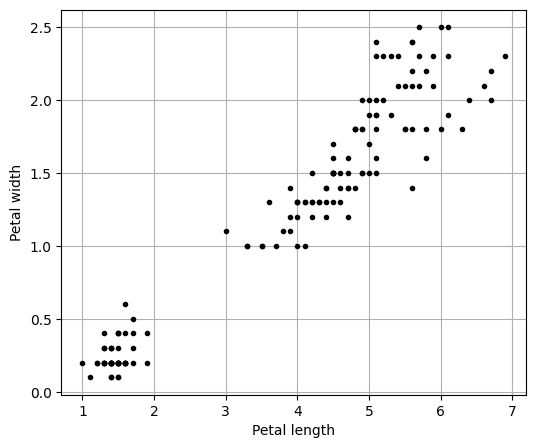

In [4]:
plt.figure(figsize=(6, 5))
plt.scatter(X[:, 2], X[:, 3], c="k", marker=".")
plt.xlabel("Petal length")
plt.ylabel("Petal width")
plt.gca().set_axisbelow(True)
plt.grid()

plt.show()

# KMeans Clustering

## Fit Predict ke Dataset

In [5]:
k = 3
X_petal = X[:, 2:] # Hanya mengambil fitur petal saja
kmeans = KMeans(n_clusters=k)
y_pred = kmeans.fit_predict(X_petal)

print(kmeans.cluster_centers_)

[[1.462      0.246     ]
 [5.59583333 2.0375    ]
 [4.26923077 1.34230769]]


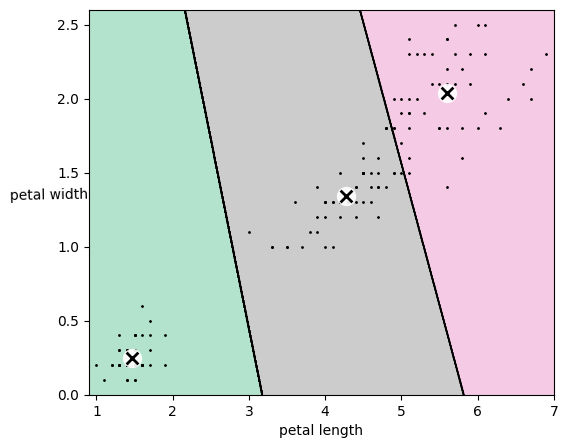

In [6]:
plt.figure(figsize=(6, 5))
plot_decision_boundaries(kmeans, X_petal)
plt.show()

## Evaluasi Kmeans dengan nilai inersia

In [7]:
print("Nilai inersia dari model KMeans Clustering: ", kmeans.inertia_)

Nilai inersia dari model KMeans Clustering:  31.37135897435897


## Prediksi Data Baru tanpa Pelatihan Ulang

In [8]:
X_new = np.array([[1, 2], [3, 2], [2, 0], [3, 2.5], [6, 2]])
y_X_new = kmeans.predict(X_new)

print(y_X_new)

[0 2 0 2 1]


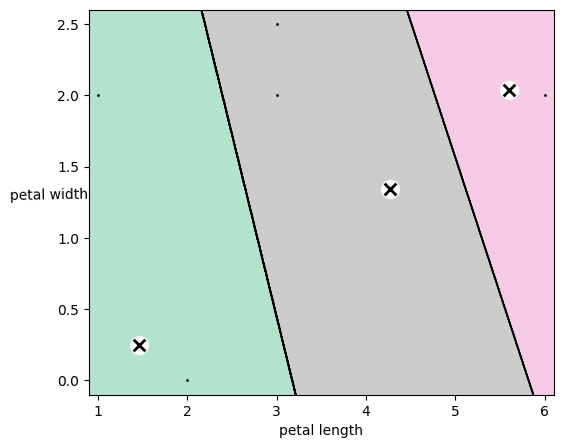

In [9]:
plt.figure(figsize=(6, 5))
plot_decision_boundaries(kmeans, X_new)
plt.show()

In [10]:
print("Jarak tiap pusat cluster dengan data baru:")
np.linalg.norm(np.tile(X_new, (1, k)).reshape(-1, k, 2)
               - kmeans.cluster_centers_, axis=2).round(2)

Jarak tiap pusat cluster dengan data baru:


array([[1.81, 4.6 , 3.33],
       [2.33, 2.6 , 1.43],
       [0.59, 4.13, 2.64],
       [2.73, 2.64, 1.72],
       [4.87, 0.41, 1.85]])

## Elbow Method
Dalam kondisi riil, terkadang kita tidak tahu sebetulnya dataset kita ada berapa cluster sehingga perlu melakukan berbagai nilai k untuk mengetahui teknik clustering yang paling baik.

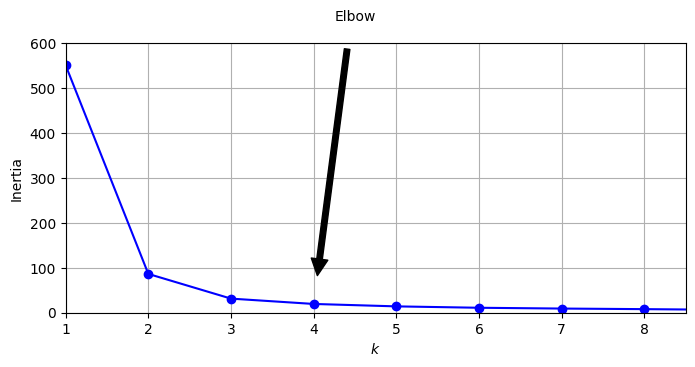

In [11]:
kmeans_per_k = [KMeans(n_clusters=k, random_state=43).fit(X_petal)
                for k in range(1, 10)]
inertias = [model.inertia_ for model in kmeans_per_k]

plt.figure(figsize=(8, 3.5))
plt.plot(range(1, 10), inertias, "bo-")
plt.xlabel("$k$")
plt.ylabel("Inertia")
plt.annotate("", xy=(4, inertias[3]), xytext=(4.45, 650),
             arrowprops=dict(facecolor='black', shrink=0.1))
plt.text(4.5, 650, "Elbow", horizontalalignment="center")
plt.axis([1, 8.5, 0, 600])
plt.grid()

plt.show()

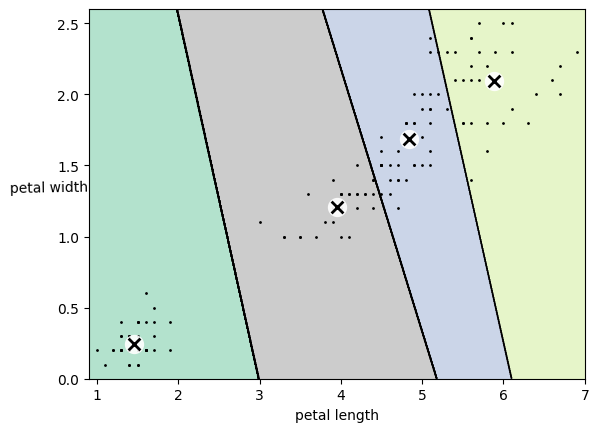

In [12]:
plot_decision_boundaries(kmeans_per_k[4 - 1], X_petal)
plt.show()

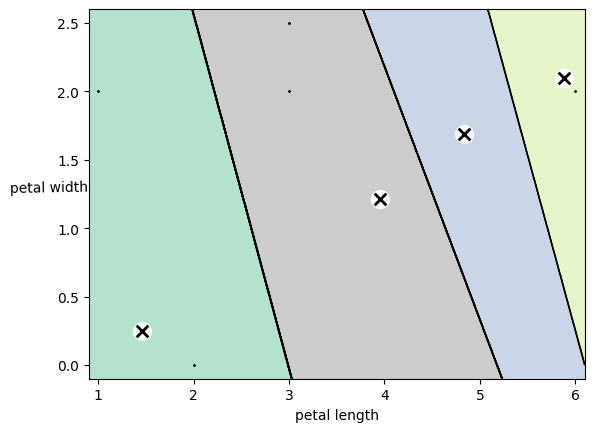

In [13]:
plot_decision_boundaries(kmeans_per_k[4 - 1], X_new)
plt.show()

## Evaluasi KMeans dengan Silhouette Score

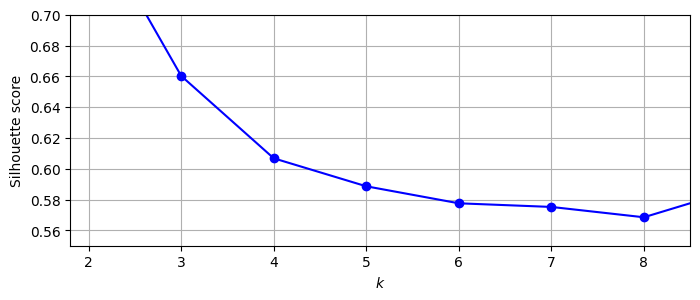

In [14]:
silhouette_scores = [silhouette_score(X_petal, model.labels_)
                     for model in kmeans_per_k[1:]]

plt.figure(figsize=(8, 3))
plt.plot(range(2, 10), silhouette_scores, "bo-")
plt.xlabel("$k$")
plt.ylabel("Silhouette score")
plt.axis([1.8, 8.5, 0.55, 0.7])
plt.grid()

plt.show()

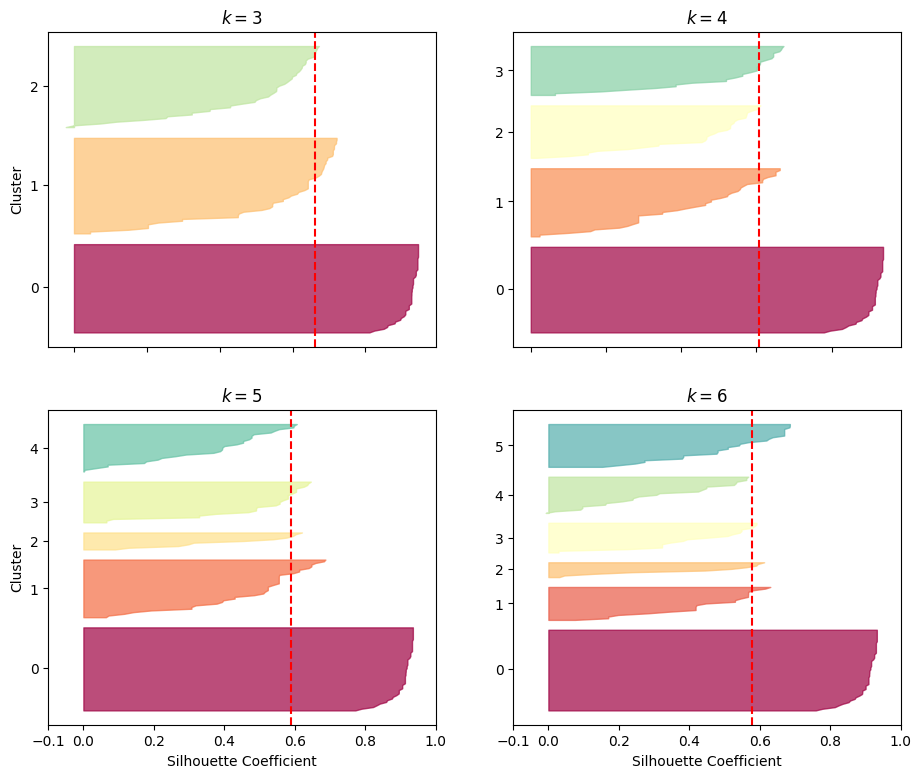

In [15]:
plt.figure(figsize=(11, 9))

for k in (3, 4, 5, 6):
    plt.subplot(2, 2, k - 2)

    y_pred = kmeans_per_k[k - 1].labels_
    silhouette_coefficients = silhouette_samples(X_petal, y_pred)

    padding = len(X_petal) // 30
    pos = padding
    ticks = []
    for i in range(k):
        coeffs = silhouette_coefficients[y_pred == i]
        coeffs.sort()

        color = plt.cm.Spectral(i / k)
        plt.fill_betweenx(np.arange(pos, pos + len(coeffs)), 0, coeffs,
                          facecolor=color, edgecolor=color, alpha=0.7)
        ticks.append(pos + len(coeffs) // 2)
        pos += len(coeffs) + padding

    plt.gca().yaxis.set_major_locator(FixedLocator(ticks))
    plt.gca().yaxis.set_major_formatter(FixedFormatter(range(k)))
    if k in (3, 5):
        plt.ylabel("Cluster")

    if k in (5, 6):
        plt.gca().set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])
        plt.xlabel("Silhouette Coefficient")
    else:
        plt.tick_params(labelbottom=False)

    plt.axvline(x=silhouette_scores[k - 2], color="red", linestyle="--")
    plt.title(f"$k={k}$")


plt.show()

# DBSCAN

## Fit Predict DBSCAN ke Dataset

In [16]:
dbscan = DBSCAN(eps=0.05)
dbscan.fit_predict(X_petal)

array([ 0,  0, -1,  1,  0, -1, -1,  1,  0, -1,  1,  2, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1,  2, -1,  1,  0,  2,  2, -1, -1,  0,
        1, -1, -1, -1, -1,  1, -1, -1, -1, -1, -1, -1,  2,  0,  1,  0, -1,
        3, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,  3, -1,
        3, -1, -1, -1, -1, -1, -1, -1, -1, -1,  3, -1, -1, -1, -1, -1,  3,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1])

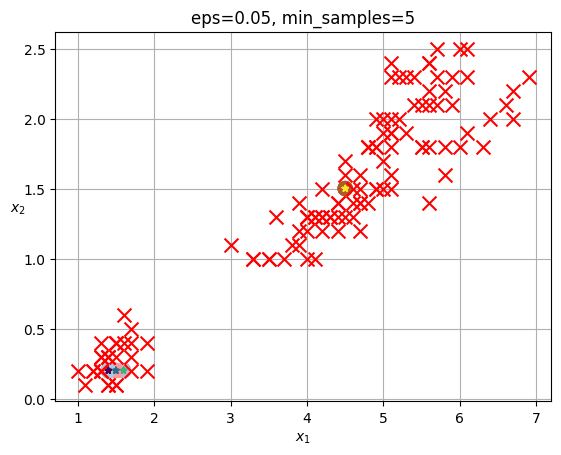

In [17]:
plot_dbscan(dbscan, X_petal, size=100)

Perbandingan pengaruh parameter epsilon pada DBSCAN


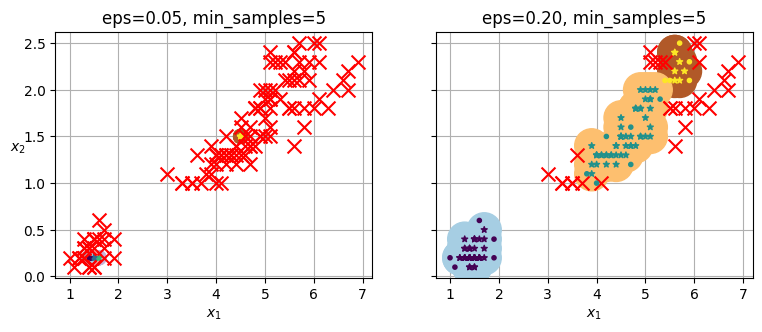

In [18]:
dbscan2 = DBSCAN(eps=0.2)
dbscan2.fit(X_petal)

print("Perbandingan pengaruh parameter epsilon pada DBSCAN")
plt.figure(figsize=(9, 3.2))

plt.subplot(121)
plot_dbscan(dbscan, X_petal, size=100)

plt.subplot(122)
plot_dbscan(dbscan2, X_petal, size=600, show_ylabels=False)

## Hyperparameter Tuning

In [19]:
eps_grid = np.linspace(0.03, 0.35, 33)
min_samples_grid = [3, 4, 5, 6]

results_df = evaluate_dbscan_grid(
    X_petal,
    eps_values=eps_grid,
    min_samples_values=min_samples_grid,
    max_noise_ratio=0.30,
    max_largest_cluster_share=0.80,
    min_cluster_size=3,
)

print("Top 10 kandidat parameter DBSCAN:")
results_df.drop(columns=["model"]).head(10)

Top 10 kandidat parameter DBSCAN:


,eps,min_samples,n_clusters,n_valid_clusters,noise_ratio,min_cluster_size,median_cluster_size,max_cluster_size,largest_cluster_share,penalty
0,0.21,4,4,4,0.0800,6,34.0,64,0.4267,0.0000
1,0.22,4,4,4,0.0800,6,34.0,64,0.4267,0.0000
2,0.30,6,3,3,0.0667,4,50.0,86,0.5733,0.0067
3,0.31,6,2,2,0.0667,50,70.0,90,0.6000,0.0067
4,0.29,6,2,2,0.0933,50,68.0,86,0.5733,0.0067
5,0.23,5,2,2,0.1000,50,67.5,85,0.5667,0.0100
6,0.24,5,2,2,0.1000,50,67.5,85,0.5667,0.0100
7,0.25,5,2,2,0.1000,50,67.5,85,0.5667,0.0100
8,0.26,5,2,2,0.1000,50,67.5,85,0.5667,0.0100
9,0.27,5,2,2,0.1000,50,67.5,85,0.5667,0.0100


## Evaluasi dengan Noise Ratio dan Jumlah Cluster

In [20]:
best_row = results_df.iloc[0]
best_dbscan = best_row["model"]
best_labels = best_dbscan.labels_

In [21]:
for c in sorted(np.unique(best_labels)):
    nama = "Noise (-1)" if c == -1 else f"Cluster {c}"
    count = int(np.sum(best_labels == c))
    print(f"  - {nama}: {count} titik ({count / len(X_petal):.2%})")

  - Noise (-1): 12 titik (8.00%)
  - Cluster 0: 50 titik (33.33%)
  - Cluster 1: 64 titik (42.67%)
  - Cluster 2: 18 titik (12.00%)
  - Cluster 3: 6 titik (4.00%)



Perbandingan hasil DBSCAN terbaik vs pembanding


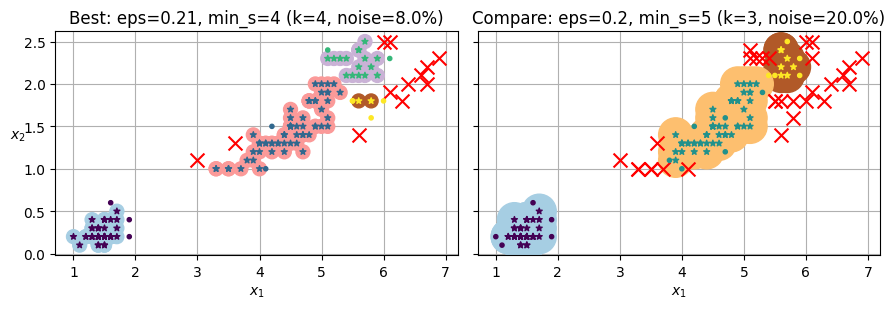

In [22]:
dbscan_compare = DBSCAN(eps=0.2, min_samples=5).fit(X_petal)

print("\nPerbandingan hasil DBSCAN terbaik vs pembanding")
plt.figure(figsize=(9, 3.2))

plt.subplot(121)
plot_dbscan(best_dbscan, X_petal, size=100)
plt.title(
    f"Best: eps={best_row['eps']}, min_s={best_row['min_samples']} "
    f"(k={best_row['n_valid_clusters']}, noise={best_row['noise_ratio']:.1%})"
)

plt.subplot(122)
plot_dbscan(dbscan_compare, X_petal, size=600, show_ylabels=False)
compare_noise = np.mean(dbscan_compare.labels_ == -1)
compare_k = len([c for c in np.unique(dbscan_compare.labels_) if c != -1])
plt.title(f"Compare: eps=0.2, min_s=5 (k={compare_k}, noise={compare_noise:.1%})")

plt.tight_layout()
plt.show()

## Prediksi Data Baru dengan KNN

In [23]:
core_X = best_dbscan.components_
core_y = best_dbscan.labels_[best_dbscan.core_sample_indices_]

if len(core_X) == 0:
    # Tidak ada core point terbentuk sama sekali
    pred_labels = np.full(len(X_new), -1, dtype=int)
else:
    n_k = min(5, len(core_X))  
    knn = KNeighborsClassifier(n_neighbors=n_k)
    knn.fit(core_X, core_y)

    dists, _ = knn.kneighbors(X_new, n_neighbors=1)
    pred_labels = knn.predict(X_new)


print(pred_labels)

[0 1 0 1 2]


# Model Lainnya

In [24]:
X_moon, y_moon = make_moons(n_samples=1000, noise=0.05, random_state=42)

In [25]:
X_moon.shape

(1000, 2)

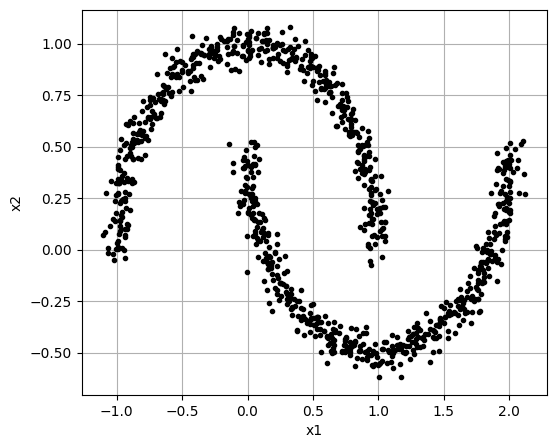

In [26]:
plt.figure(figsize=(6, 5))
plt.scatter(X_moon[:, 0], X_moon[:, 1], c="k", marker=".")
plt.xlabel("x1")
plt.ylabel("x2")
plt.gca().set_axisbelow(True)
plt.grid()

plt.show()

## KMeans

In [27]:
k = 2
kmeans_moon = KMeans(n_clusters=k)
y_pred_moon = kmeans_moon.fit_predict(X_moon)

print(kmeans_moon.cluster_centers_)

[[-0.21574166  0.57415483]
 [ 1.1889635  -0.065324  ]]


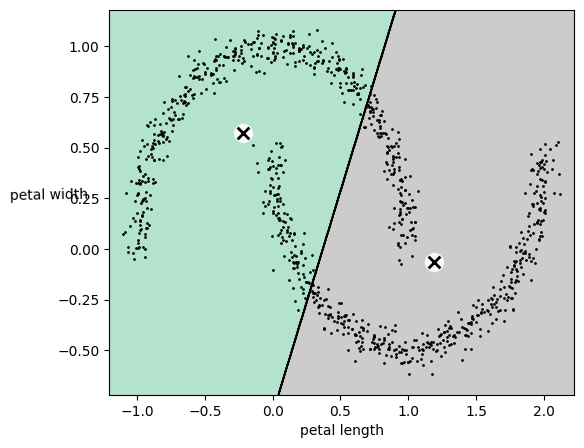

In [28]:
plt.figure(figsize=(6, 5))
plot_decision_boundaries(kmeans_moon, X_moon)
plt.show()

## DBSCAN Clustering

In [29]:
dbscan_moon = DBSCAN(eps=0.2)
dbscan_moon.fit_predict(X_moon)

array([0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1,
       1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0,
       1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0,
       0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0,
       0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0,
       1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1,
       0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1,
       1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1,
       0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0,
       1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1,
       0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1,
       1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0,
       1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0,

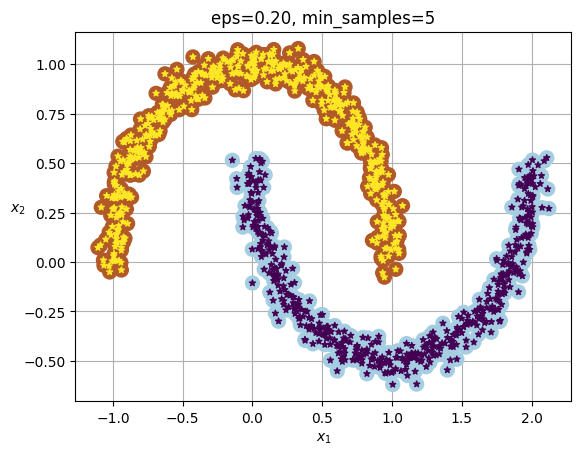

In [30]:
plot_dbscan(dbscan_moon, X_moon, size=100)

In [31]:
knn_moon = KNeighborsClassifier(n_neighbors=50)
knn_moon.fit(dbscan_moon.components_, dbscan_moon.labels_[dbscan_moon.core_sample_indices_])

X_moon_new = np.array([[-0.5, 0], [0, 0.5], [1, -0.1], [2, 1]])
knn_moon.predict(X_moon_new)

array([1, 0, 1, 0])

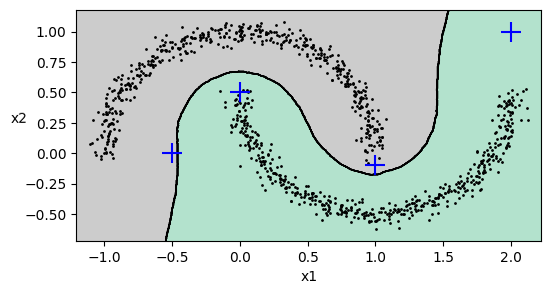

In [32]:
plt.figure(figsize=(6, 3))
plot_decision_boundaries(knn_moon, X_moon, show_centroids=False)
plt.xlabel("x1")
plt.ylabel("x2")
plt.scatter(X_moon_new[:, 0], X_moon_new[:, 1], c="b", marker="+", s=200, zorder=10)

plt.show()

## Special Clustering

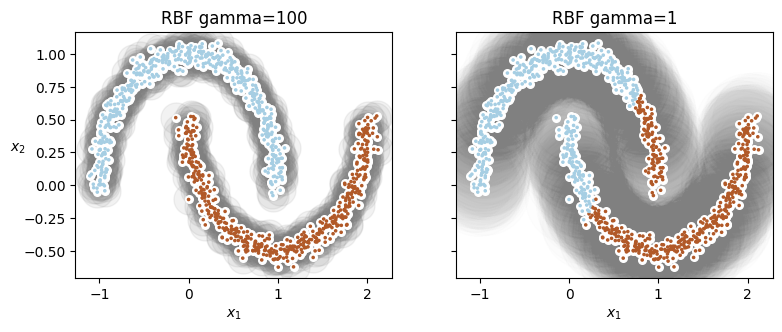

In [33]:
sc1 = SpectralClustering(n_clusters=2, gamma=100, random_state=42)
sc1.fit(X_moon)

sc2 = SpectralClustering(n_clusters=2, gamma=1, random_state=42)
sc2.fit(X_moon)

plt.figure(figsize=(9, 3.2))

plt.subplot(121)
plot_spectral_clustering(sc1, X_moon, size=500, alpha=0.1)

plt.subplot(122)
plot_spectral_clustering(sc2, X_moon, size=4000, alpha=0.01, show_ylabels=False)

plt.show()

## Gaussian Mixture

In [34]:
gm = GaussianMixture(n_components=3, n_init=10, random_state=42)
gm.fit(X_moon)

gm.precisions_

array([[[  7.64858868,   2.57792932],
        [  2.57792932,   4.35085856]],

       [[ 81.35366831, -61.53759275],
        [-61.53759275,  57.87180524]],

       [[ 94.23650918, -64.86156698],
        [-64.86156698,  55.78957972]]])

/tmp/ipykernel_16/4234830240.py:181: UserWarning: Log scale: values of z <= 0 have been masked
  plt.contourf(xx, yy, Z,
/tmp/ipykernel_16/4234830240.py:184: UserWarning: Log scale: values of z <= 0 have been masked
  plt.contour(xx, yy, Z,


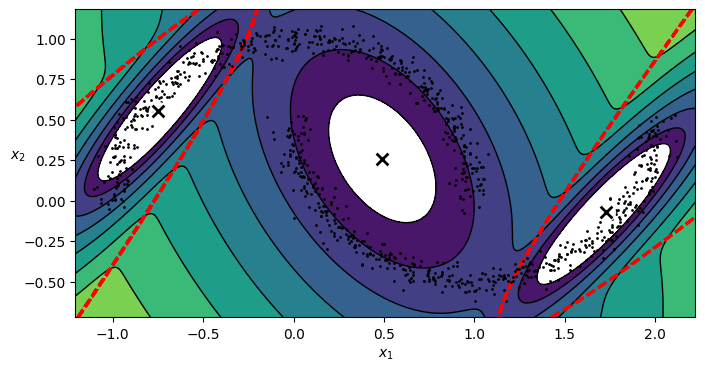

In [35]:
plt.figure(figsize=(8, 4))
plot_gaussian_mixture(gm, X_moon)
plt.show()

## Agglomerative Clustering

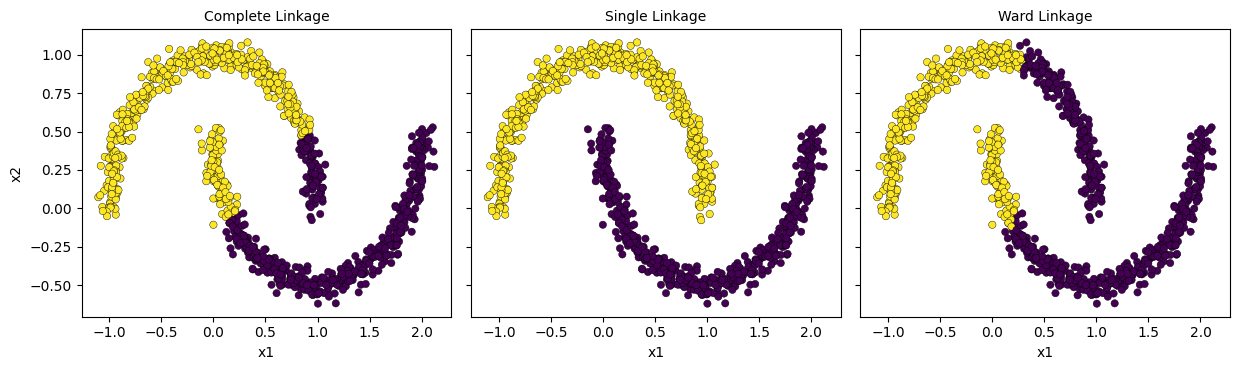

In [36]:
agg_complete = AgglomerativeClustering(n_clusters=2, linkage="complete")
labels_complete = agg_complete.fit_predict(X_moon)

models = {
    'Complete Linkage': AgglomerativeClustering(
        n_clusters=2, linkage="complete"
    ),
    "Single Linkage": AgglomerativeClustering(n_clusters=2, linkage="single"),
    "Ward Linkage": AgglomerativeClustering(n_clusters=2, linkage="ward"),
}

fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.8), sharex=True, sharey=True)

for ax, (title, model) in zip(axes, models.items()):
    labels = model.fit_predict(X_moon)
    ax.scatter(X_moon[:, 0], X_moon[:, 1], c=labels, cmap="viridis", s=28, edgecolors="k", linewidths=0.3)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("x1")

axes[0].set_ylabel("x2")
plt.tight_layout()
plt.show()

# Latihan

1. Load ulang dataset Iris, gunakan Sepal Length dan Sepal Width sebagai fitur yang akan diklasterisasi.
   -

2. Gunakan Elbow Method dan model KMeans untuk mencari cluster terbaik.
   -

3. Bandingkan performa model dengan penggunaan fitur Petal Length dan Petal Width. Fitur mana yang paling baik dalam melakukan clustering?
   -

4. Lakukan eksperimen KMeans Clustering dengan menggunakan keempat fitur dataset Iris. Apakah performa model meningkat, menurun, atau tetap?
   -

5. Lakukan eksperimen DBSCAN yang membandingkan fitur Petal, Sepal, dan keduanya pada dataset Iris. Bagaimana performa model DBSCAN pada perubahan fitur yang digunakan?
   -

6. Lakukan eksperimen Agglomerative Clustering pada dataset Iris. Pemilihan fitur dibebaskan dengan diberikan justifikasinya. Bagaimana hasil model Agglomerative Clustering pada eksperimen tersebut?
   -